# 05 Truth lag: how long until the record shows the truth?

| | |
|---|---|
| **Question** | After an edit is saved, how long until we can see that it will be reverted? What does waiting buy a RAG crawler, by revert-risk decile? And how many September edits were reverted after the dump? |
| **Answer** | History: <!--fact:mongo_q5_history_known_1h_pct-->55.66<!--/fact-->% of the eventual reverts (within 4 days) are visible after 1 hour, <!--fact:mongo_q5_history_known_1d_pct-->88.96<!--/fact-->% after 1 day. Top risk decile (live): <!--fact:risk_top_decile_revert_rate_pct-->31.66<!--/fact-->% reverted, <!--fact:risk_top_decile_visible_1h_pct-->69.24<!--/fact-->% of those visible after 1 hour. At least <!--fact:late_reverts_rows-->3,205<!--/fact--> late reverts in all namespaces (<!--fact:late_reverts_rows_ns0-->2,662<!--/fact--> in namespace 0; lower bounds). Live numbers are **PROVISIONAL**. |
| **Time to run** | about 30 seconds (Mongo Q5 and the risk deciles run on MongoDB) |
| **Needs** | the local MongoDB (Docker) and `data/tables/` (late reverts, live revisions). |

Human editors appear only as pseudonyms (`editor_` + 10 hex digits). Bots keep their names. All data times are UTC. Words: see `GLOSSARY.md`. Numbers: see `report/FACTS.md`. Every number in the text comes from there (`report/sync_notebook_text.py` copies it).

## Setup

**What:** Finds the project folder, imports `config.py` and the report helpers, and prints the data version.

**Why:** Every rule and path comes from `config.py`. The data version tells you which data release you have.

**You should see:** `DATA_VERSION: data-v1` (or a later version) and the path of the Python program.

In [1]:
# Set up the paths: this notebook is in ec-hw2/notebooks/, the project code is in ec-hw2/.
import sys, time, json
from pathlib import Path
HW2 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ec-hw2"
sys.path.insert(0, str(HW2))
import config
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, Markdown, display
from report import build_facts as facts      # FACTS.md helpers (check, tables with pseudonyms)
from report import make_figures as figs      # the report charts
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
T0 = time.time()

def _cell(v):
    if v is None or v is pd.NA or (isinstance(v, float) and v != v):
        return ""
    if isinstance(v, float):
        return f"{v:,.1f}" if abs(v) >= 1000 else f"{v:.4g}"
    return v

def show(df, n=None):
    """Print a table as text (it reads well on GitHub). Each cell keeps its own type."""
    d = df if n is None else df.head(n)
    rows = [[_cell(v) for v in r] for r in d.astype(object).itertuples(index=False)]
    print(tabulate(rows, headers=list(d.columns), tablefmt="github"))

print("DATA_VERSION:", config.DATA_VERSION)
print("Python:", sys.executable)

DATA_VERSION: data-v1
Python: /Users/scottnelson/Desktop/226/truth-lag/.venv/bin/python3


## 1. Are the stream labels of the live cohort final?

**What:** Reads `data/tables/_SUCCESS_live.json` and says if the stream labels of the live cohort are final. It also shows how long each live edit has been followed so far.

**Why:** A live edit counts as 'reverted' only when a revert came within 4 days. Until the capture has passed <!--fact:live_final_after-->2026-10-27T00:05:00Z<!--/fact-->, some of those 4 days are still in the future, so the live numbers will change.

**You should see:** A PROVISIONAL warning (until the live refresh after Mon 2026-10-26 5:05 PM PT), the newest parsed event (<!--fact:live_newest_meta_dt-->2026-10-24T07:59:59Z<!--/fact-->), and the follow-up of the live edits: from <!--fact:live_followup_min_d-->1.33<!--/fact--> to <!--fact:live_followup_max_d-->4.33<!--/fact--> days. Only <!--fact:live_followup_ge_4d_pct-->11.35<!--/fact-->% of the live edits are followed for 4 days or more.

In [2]:
sl = json.loads((config.TABLES_DIR / "_SUCCESS_live.json").read_text())
fu = pd.read_parquet(config.TABLES_DIR / "live_revisions.parquet", columns=["followup_s"])["followup_s"] / 86400
if sl.get("provisional", True):
    display(Markdown(f"> **PROVISIONAL.** The stream labels of the live cohort are final only after {sl['live_final_after']}. "
                     f"The newest parsed event is {sl['newest_meta_dt']}. Every live number below can still change."))
else:
    display(Markdown("> **FINAL.** The stream labels of the live cohort are final."))
print(f"follow-up of the live edits: min {fu.min():.2f} d, median {fu.median():.2f} d, max {fu.max():.2f} d "
      f"(the label needs {config.LIVE_FOLLOWUP_DAYS} d); share followed for 4 days or more: {100 * (fu >= 4).mean():.1f}%")

> **PROVISIONAL.** The stream labels of the live cohort are final only after 2026-10-27T00:05:00Z. The newest parsed event is 2026-10-24T07:59:59.973000Z. Every live number below can still change.

follow-up of the live edits: min 1.33 d, median 2.77 d, max 4.33 d (the label needs 4 d); share followed for 4 days or more: 11.4%


## 2. Known-by curves

**What:** Runs Mongo Q5 (`queries/mongo/q5_truth_lag_preview.json`) and draws the known-by curves: the share of eventual reverts (within 4 days) already visible after each wait, for both cohorts.

**Why:** This is the truth-lag preview: how much of the final label is known after 1 minute, 1 hour, 1 day.

**You should see:** History <!--fact:mongo_q5_history_known_1h_pct-->55.66<!--/fact-->% after 1 h; live <!--fact:mongo_q5_live_known_1h_pct-->59.83<!--/fact-->% (PROVISIONAL; too high while the follow-up is short). Then the figure.

Mongo Q5 ran in 15.0 s
| wait   |   history |   live |
|--------|-----------|--------|
| 0      |       0   |    0   |
| 1 min  |      19.9 |   23.1 |
| 5 min  |      35.2 |   40.3 |
| 15 min |      43.8 |   48.7 |
| 1 h    |      55.7 |   59.8 |
| 6 h    |      73.1 |   77.7 |
| 1 d    |      89   |   92.3 |
| 2 d    |      94.8 |   96.5 |
| 4 d    |     100   |  100   |


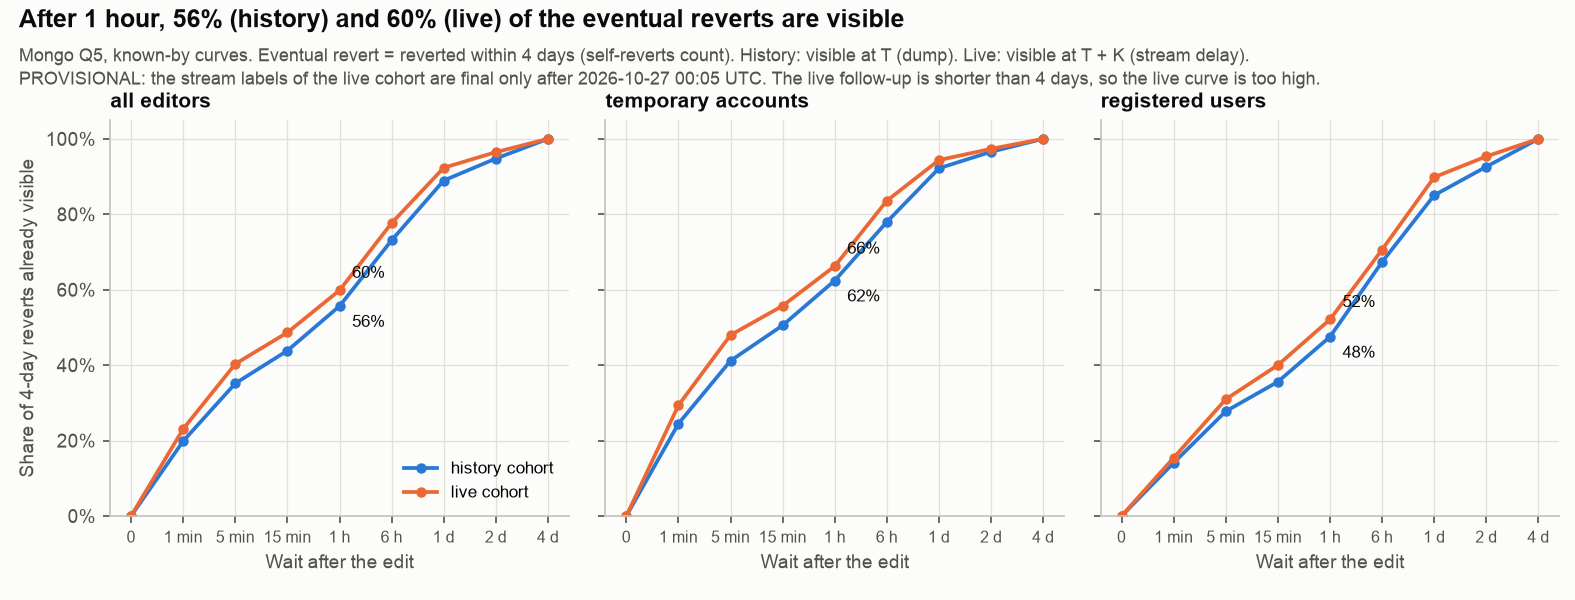

In [3]:
from queries import run_mongo
from load_mongo import connect
db = connect(config.MONGO_URI, 5000)[config.MONGO_DB]
spec = run_mongo.load_query(HW2 / "queries" / "mongo" / "q5_truth_lag_preview.json")
t = time.perf_counter()
q5 = run_mongo.flatten("q5_truth_lag_preview", run_mongo.run_pipeline(db, spec["collection"], spec["pipeline"], True))
print(f"Mongo Q5 ran in {time.perf_counter() - t:.1f} s")
known = q5[""]
wide = known[known["user_kind"] == "all"].pivot(index="wait", columns="cohort", values="share_known")
wide = (100 * wide).round(1).reindex(list(config.WAIT_POINTS_S)).reset_index()
show(wide)
display(Image(filename=str(figs.known_by_figure(known))))

## 3. The RAG-crawler decision table

**What:** Runs the risk-decile pipeline (`queries/run_mongo.py`, `risk_deciles_pipeline`) on the live cohort. Then it builds the RAG-crawler decision table (`report/build_facts.py`, `decision_table`). For each revert-risk decile, the table gives:
- n and the revert rate (within 4 days);
- the share of its eventual reverts that are already visible after 1 hour and after 1 day;
- the chance that an edit that is still clean at that time is reverted later.

Each share has a Wilson 95% interval. A last group, 'no score', holds the edits without a revert-risk score.

**Why:** The Impact persona is a RAG-crawler engineer: she must decide how long to wait before she copies an edit. This table is her decision input. It uses the Wikimedia revert-risk score that arrives about 3 seconds after the edit.

**You should see:** 10 deciles + 'no score'. The top decile: <!--fact:risk_top_decile_revert_rate_pct-->31.66<!--/fact-->% reverted, <!--fact:risk_top_decile_visible_1h_pct-->69.24<!--/fact-->% of those visible after 1 h; the bottom decile <!--fact:risk_bottom_decile_revert_rate_pct-->0.07<!--/fact-->%. The 'no score' group (<!--fact:risk_no_score_edits-->10,450<!--/fact--> edits, <!--fact:risk_no_score_revert_rate_pct-->1.52<!--/fact-->% reverted) mixes two kinds of edits: <!--fact:risk_no_score_page_creations-->5,392<!--/fact--> page creations (<!--fact:risk_no_score_page_creations_reverted-->0<!--/fact--> reverted; no page creation has a score) and <!--fact:risk_no_score_not_captured-->5,058<!--/fact--> edits whose score event was not captured (<!--fact:risk_no_score_not_captured_revert_rate_pct-->3.14<!--/fact-->% reverted). All PROVISIONAL. Then the figure.

risk deciles ran in 7.4 s
same n and reverts as results/mongo_q5_risk_deciles.csv: yes
'no score' group: 10,450 edits = 5,392 page creations (0 reverted) + 5,058 edits whose score event was not captured (159 reverted, 3.14%)
| risk group   | risk score   |   edits (n) |   reverts in 4 d (n) | revert rate   | visible after 1 h [95% CI]   | visible after 1 d [95% CI]   | reverted later if clean at 1 h [95% CI]   | reverted later if clean at 1 d [95% CI]   |
|--------------|--------------|-------------|----------------------|---------------|------------------------------|------------------------------|-------------------------------------------|-------------------------------------------|
| decile 1     | 0.00-0.06    |      26,902 |                   19 | 0.07%         | 63.2% (41.0-80.9)            | 100.0% (83.2-100.0)          | 0.03% (0.01-0.05)                         | 0.00% (0.00-0.01)                         |
| decile 2     | 0.06-0.12    |      26,902 |                  103 | 0

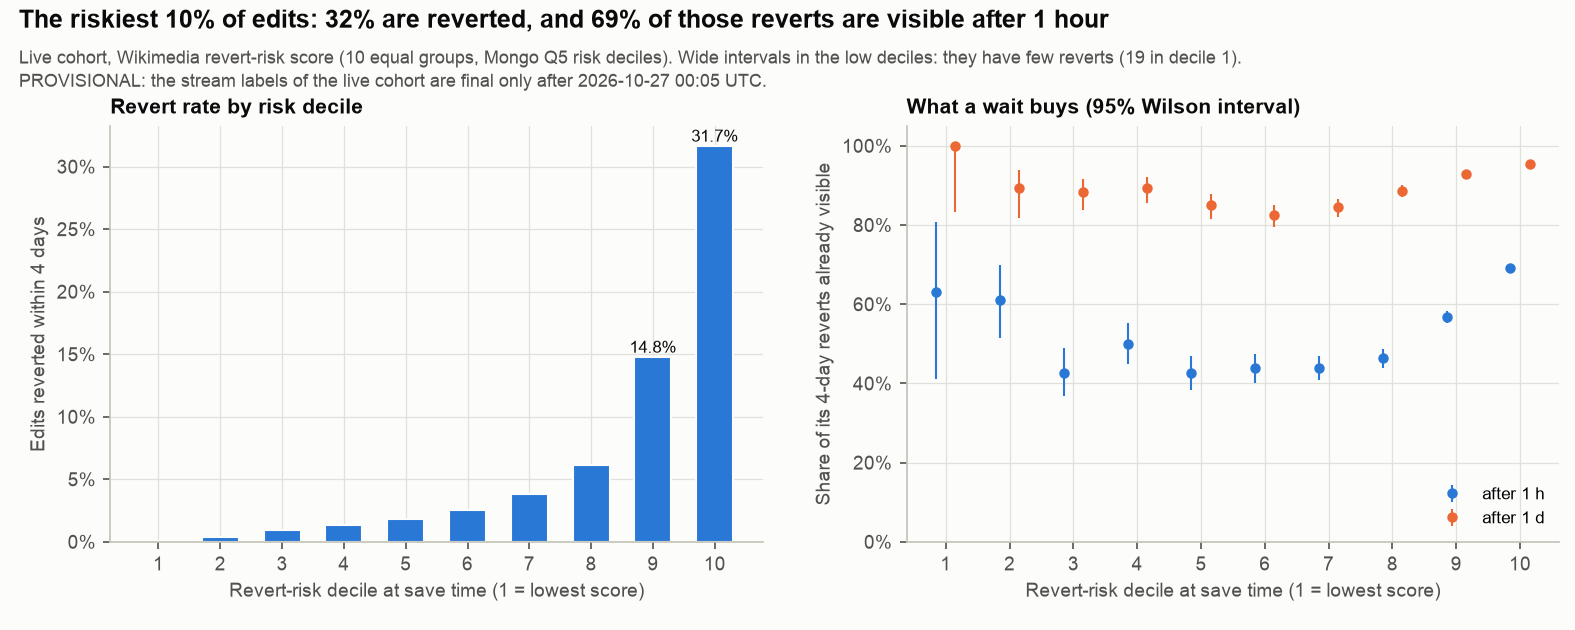

In [4]:
t = time.perf_counter()
dec_out = run_mongo.run_pipeline(db, config.COL_REVISIONS, run_mongo.risk_deciles_pipeline(), True)
deciles = pd.DataFrame(run_mongo.decile_rows(dec_out))
print(f"risk deciles ran in {time.perf_counter() - t:.1f} s")
saved = pd.read_csv(config.RESULTS_DIR / "mongo_q5_risk_deciles.csv")
same = deciles[["group", "n", "n_reverted_4d"]].reset_index(drop=True).equals(saved[["group", "n", "n_reverted_4d"]])
print("same n and reverts as results/mongo_q5_risk_deciles.csv:", "yes" if same else "NO")
# The 'no score' group mixes page creations and edits whose score event was not captured.
lv = pd.read_parquet(config.TABLES_DIR / "live_revisions.parquet", columns=["rev_id", "parent_id", "revert_risk"])
lk = pd.read_parquet(config.TABLES_DIR / "live_revert_links.parquet", columns=["reverted_rev_id", "within_followup"])
no = lv[lv["revert_risk"].isna()]
created = no["parent_id"].isna() | (no["parent_id"] == 0)
rev4 = no["rev_id"].isin(lk.loc[lk["within_followup"], "reverted_rev_id"])
print(f"'no score' group: {len(no):,} edits = {int(created.sum()):,} page creations ({int((created & rev4).sum())} reverted) "
      f"+ {int((~created).sum()):,} edits whose score event was not captured ({int((~created & rev4).sum())} reverted, "
      f"{100 * (~created & rev4).sum() / (~created).sum():.2f}%)")
dt = facts.decision_table(deciles)
show(facts.decision_table_text(dt))
display(Image(filename=str(figs.risk_decile_figure(dt))))

## 4. Late reverts (case study)

**What:** The late-revert case study: September revisions that the 2026-09 dump says are not reverted, but that the October stream shows being reverted. Counts by class, for all namespaces and for namespace 0 only (like the history cohort). Then 3 examples (one per class; human editors as pseudonyms; `report/build_facts.py`, `late_examples`).

**Why:** It links the two cohorts: a dump label is a snapshot, and it can change later. The classes: `exact` (the label will change in the next dump), `inexact_undo` (the dump never counts it), `method_unknown` (only the `mw-reverted` tag was seen).

**You should see:**
- All namespaces: <!--fact:late_reverts_rows-->3,205<!--/fact--> rows (exact <!--fact:late_reverts_exact-->1,928<!--/fact-->, inexact_undo <!--fact:late_reverts_inexact_undo-->94<!--/fact-->, method_unknown <!--fact:late_reverts_method_unknown-->1,183<!--/fact-->).
- Namespace 0 only: <!--fact:late_reverts_rows_ns0-->2,662<!--/fact--> rows (exact <!--fact:late_reverts_exact_ns0-->1,645<!--/fact-->, inexact_undo <!--fact:late_reverts_inexact_undo_ns0-->91<!--/fact-->, method_unknown <!--fact:late_reverts_method_unknown_ns0-->926<!--/fact-->).
- All counts are lower bounds. Then 3 example rows and the figure.

| class          |   revisions (all namespaces) |   namespace 0 |   in the history cohort |
|----------------|------------------------------|---------------|-------------------------|
| exact          |                         1928 |          1645 |                      85 |
| method_unknown |                         1183 |           926 |                      80 |
| inexact_undo   |                           94 |            91 |                       6 |

total 3,205 September revisions on 1,817 pages, all namespaces; 2,662 in namespace 0 (lower bounds)
All counts are lower bounds: nobody watched the stream from 2026-10-01T01:38:27Z (the dump's last revision) until the capture started (page_change: 2026-10-19T23:00:00.504000Z, tags: 2026-10-17T01:30:18.742000Z).

| class          | page_title                      | edit_utc             | dump_says_reverted   | first_stream_signal_utc   |   age_days | author                        | reverter                      | method    | via      

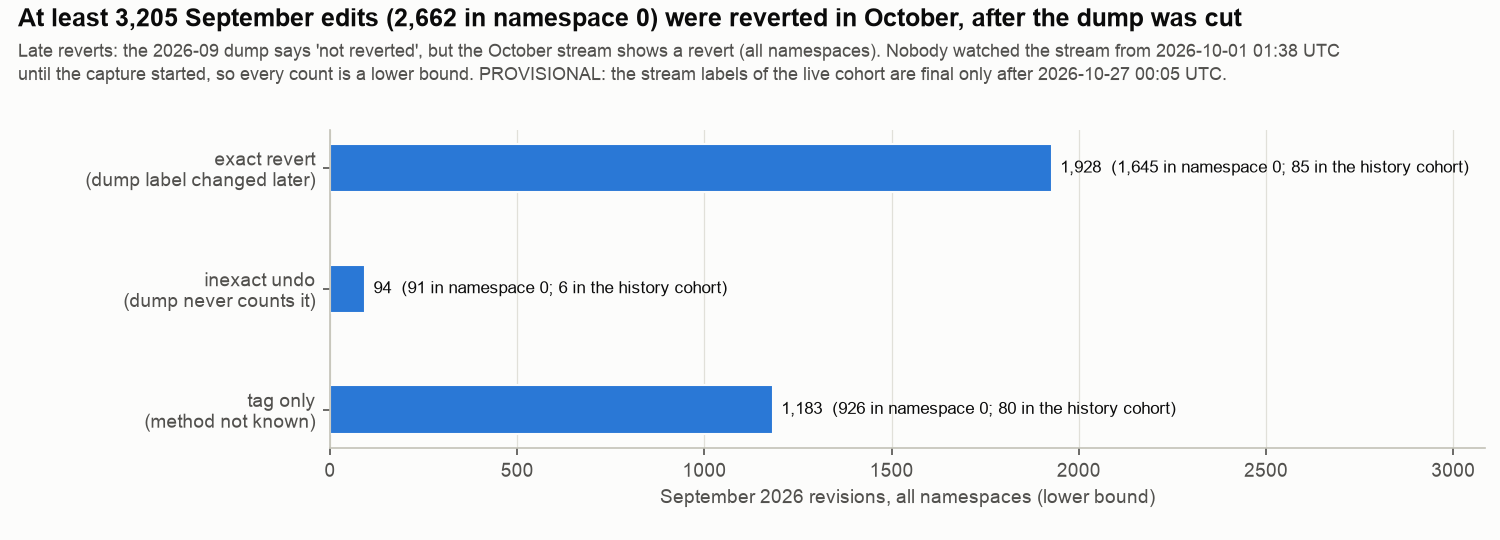

In [5]:
late = pd.read_parquet(config.TABLES_DIR / "late_reverts.parquet")
lr = json.loads((config.TABLES_DIR / "late_reverts_summary.json").read_text())
ns0 = late["page_ns"].eq(0).fillna(False).astype(bool)
by = pd.DataFrame({"revisions (all namespaces)": late["class"].value_counts(),
                   "namespace 0": late[ns0]["class"].value_counts(),
                   "in the history cohort": late[late["in_history_cohort"]]["class"].value_counts()}).fillna(0).astype(int)
show(by.reset_index(names="class"))
print(f"\ntotal {len(late):,} September revisions on {late['page_id'].nunique():,} pages, all namespaces; "
      f"{int(ns0.sum()):,} in namespace 0 (lower bounds)")
print(lr["lower_bound_note"])
print()
ex = facts.late_examples()
show(ex)
display(Image(filename=str(figs.late_reverts_figure(lr))))

## Check against FACTS.md

**What:** Compares the key numbers of this notebook with `report/FACTS.md`. Then it checks every number in the text of this notebook (the fact markers) against FACTS.md.

**Why:** The report uses FACTS.md. If a number here is different, the data or the code changed: tell the Report+GenAI owner before you copy any number.

**You should see:** Two tables with one row per number, and the lines `OK: all ... numbers match FACTS.md` and `OK: all ... numbers in the text match FACTS.md`. `DIFFERENT` means a number changed (normal for PROVISIONAL numbers after the live refresh). Then run `report/build_facts.py` and `report/sync_notebook_text.py` again.

In [6]:
kh = known[(known["cohort"] == "history") & (known["user_kind"] == "all")].set_index("wait")
kl = known[(known["cohort"] == "live") & (known["user_kind"] == "all")].set_index("wait")
top_d = dt[dt["group"] != "no score"].iloc[-1]
bottom_d = dt[dt["group"] != "no score"].iloc[0]
facts.check({
    "mongo_q5_history_known_1min_pct": 100 * kh.loc["1 min", "share_known"],
    "mongo_q5_history_known_1h_pct": 100 * kh.loc["1 h", "share_known"],
    "mongo_q5_history_known_1d_pct": 100 * kh.loc["1 d", "share_known"],
    "mongo_q5_live_known_1h_pct": 100 * kl.loc["1 h", "share_known"],
    "mongo_q5_live_known_1d_pct": 100 * kl.loc["1 d", "share_known"],
    "risk_top_decile_edits": top_d["edits"],
    "risk_top_decile_revert_rate_pct": top_d["revert_rate_4d_pct"],
    "risk_top_decile_visible_1h_pct": top_d["visible_1h_pct"],
    "risk_top_decile_visible_1d_pct": top_d["visible_1d_pct"],
    "risk_top_decile_later_1h_pct": top_d["later_1h_pct"],
    "risk_bottom_decile_revert_rate_pct": bottom_d["revert_rate_4d_pct"],
    "late_reverts_rows": len(late),
    "late_reverts_exact": int((late["class"] == "exact").sum()),
    "late_reverts_inexact_undo": int((late["class"] == "inexact_undo").sum()),
    "late_reverts_method_unknown": int((late["class"] == "method_unknown").sum()),
    "late_reverts_in_history_cohort": int(late["in_history_cohort"].sum()),
    "late_reverts_rows_ns0": int(ns0.sum()),
    "late_reverts_exact_ns0": int((late[ns0]["class"] == "exact").sum()),
    "late_reverts_inexact_undo_ns0": int((late[ns0]["class"] == "inexact_undo").sum()),
    "late_reverts_method_unknown_ns0": int((late[ns0]["class"] == "method_unknown").sum()),
    "risk_no_score_page_creations": int(created.sum()),
    "risk_no_score_not_captured": int((~created).sum()),
    "risk_no_score_not_captured_reverted": int((~created & rev4).sum()),
    "live_followup_ge_4d_pct": 100 * (fu >= config.LIVE_FOLLOWUP_DAYS).mean(),
    "live_followup_max_d": fu.max(),
})
print()
from report import sync_notebook_text
sync_notebook_text.check_markers(HW2 / "notebooks" / "05_truth_lag.ipynb")
print(f"\nnotebook time: {time.time() - T0:.0f} s")

| key                                 | FACTS.md   | notebook   | status      | result   |
|-------------------------------------|------------|------------|-------------|----------|
| mongo_q5_history_known_1min_pct     | 19.87      | 19.87      | FINAL       | OK       |
| mongo_q5_history_known_1h_pct       | 55.66      | 55.66      | FINAL       | OK       |
| mongo_q5_history_known_1d_pct       | 88.96      | 88.96      | FINAL       | OK       |
| mongo_q5_live_known_1h_pct          | 59.83      | 59.83      | PROVISIONAL | OK       |
| mongo_q5_live_known_1d_pct          | 92.33      | 92.33      | PROVISIONAL | OK       |
| risk_top_decile_edits               | 26,898     | 26,898     | PROVISIONAL | OK       |
| risk_top_decile_revert_rate_pct     | 31.66      | 31.66      | PROVISIONAL | OK       |
| risk_top_decile_visible_1h_pct      | 69.24      | 69.24      | PROVISIONAL | OK       |
| risk_top_decile_visible_1d_pct      | 95.30      | 95.30      | PROVISIONAL | OK       |

Numbers in the text of 05_truth_lag.ipynb (fact markers):
| cell   | key                                        | text                 | FACTS.md             | result   |
|--------|--------------------------------------------|----------------------|----------------------|----------|
| 0      | mongo_q5_history_known_1h_pct              | 55.66                | 55.66                | OK       |
| 0      | mongo_q5_history_known_1d_pct              | 88.96                | 88.96                | OK       |
| 0      | risk_top_decile_revert_rate_pct            | 31.66                | 31.66                | OK       |
| 0      | risk_top_decile_visible_1h_pct             | 69.24                | 69.24                | OK       |
| 0      | late_reverts_rows                          | 3,205                | 3,205                | OK       |
| 0      | late_reverts_rows_ns0                      | 2,662                | 2,662                | OK       |
| 3      | live_final_after           